In [1]:
import glob, pickle, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['pdf.fonttype'] = 42

In [2]:
Fs = 3e4
out_path = './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/'

files_to_analyze = glob.glob(out_path + '*_EncodingModel.pickle')

In [3]:
files_to_analyze

['./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m29_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m30_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m29_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m11_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m31_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/m11_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/Uns

In [6]:
deg_amp, volt_amp = [], []     # max-magnitude deflection per unit

av_max = []
av_max_bin = []
local_max = []
local_max_bin_pre = []
local_max_bin_post = []
mothID = []

for fp in files_to_analyze:
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    mothID.append(ID)
    print(f'working on {ID}')
    
    fname = os.path.basename(fp)
    with open(fp, 'rb') as f:
        data = pickle.load(f)
        p_spike = np.asarray(data[13]).ravel()    # index 1 = STA
        bins = np.asarray(data[12]).ravel()
        
        derivatives = np.gradient(p_spike, bins)
        max_steepness_idx = np.argmax(derivatives)
        max_steepness = derivatives[max_steepness_idx]
        
        av_max.append(max_steepness)
        av_max_bin.append(bins[max_steepness_idx])
        
        print(f"Max steepness: {max_steepness}")
        print(f"At bin: {bins[max_steepness_idx]}")

        # Also let's check consecutive differences just in case we want the local point-to-point max slope
        dx = np.diff(bins)
        dp = np.diff(p_spike)
        slopes = dp / dx
        max_slope_idx = np.argmax(slopes)
        
        local_max.append(slopes[max_slope_idx])
        local_max_bin_pre.append(bins[max_slope_idx])
        local_max_bin_post.append(bins[max_slope_idx+1])
        print(f"Max point-to-point slope: {slopes[max_slope_idx]} between {bins[max_slope_idx]} and {bins[max_slope_idx+1]}")

data = pd.DataFrame({'mothID': mothID, 
                    'av_max': av_max,
                     'av_max_bin': av_max_bin,
                     'local_max': local_max,
                     'local_max_bin_pre': local_max_bin_pre,
                     'local_max_bin_post': local_max_bin_post
                    })
os.makedirs('./dataFolder/SummaryValuesFinal', exist_ok=True); data.to_csv('./dataFolder/SummaryValuesFinal/nld_curvature_summary.csv', index=False)

working on m29_unit_2
Max steepness: 0.0027122084905759256
At bin: 1.9482980718485599
Max point-to-point slope: 0.0027122084905759256 between 1.4824954236283756 and 1.9482980718485599
working on m30_unit_2
Max steepness: 0.0007508752600816687
At bin: 1.8261383131067497
Max point-to-point slope: 0.0007508752600816687 between 1.403075281717677 and 1.8261383131067497
working on m31_unit_3
Max steepness: 0.000449347485191091
At bin: 1.0225564945455936
Max point-to-point slope: 0.00046566947847230414 between 1.0225564945455936 and 1.4560248191424172
working on m29_unit_3
Max steepness: 0.00866757211171326
At bin: 2.293637689624181
Max point-to-point slope: 0.00866757211171326 between 1.8152647988924584 and 2.293637689624181
working on m11_unit_1
Max steepness: 0.0029374143615249486
At bin: 0.8150512253711981
Max point-to-point slope: 0.003618902628177979 between 0.8150512253711981 and 1.2718283989304537
working on m31_unit_2
Max steepness: 0.004258091157122648
At bin: 2.301729383518439
Max 

In [7]:
data

,mothID,av_max,av_max_bin,local_max,local_max_bin_pre,local_max_bin_post
0,m29_unit_2,0.002712,1.948298,0.002712,1.482495,1.948298
1,m30_unit_2,0.000751,1.826138,0.000751,1.403075,1.826138
2,m31_unit_3,0.000449,1.022556,0.000466,1.022556,1.456025
3,m29_unit_3,0.008668,2.293638,0.008668,1.815265,2.293638
4,m11_unit_1,0.002937,0.815051,0.003619,0.815051,1.271828
5,m31_unit_2,0.004258,2.301729,0.004258,1.844127,2.301729
6,m31_unit_1,0.002004,0.469484,0.002490,0.014782,0.469484
7,m11_unit_2,0.002670,2.122038,0.002670,1.675877,2.122038
8,m23_unit_1,0.006018,1.279676,0.006430,1.279676,1.752958
9,m30_unit_1,0.003342,2.074367,0.003342,1.637812,2.074367


{'whiskers': [<matplotlib.lines.Line2D at 0x2e1299f3680>,
 'caps': [<matplotlib.lines.Line2D at 0x2e1299f3c50>,
 'boxes': [<matplotlib.lines.Line2D at 0x2e1299f3380>],
 'medians': [<matplotlib.lines.Line2D at 0x2e129a2c2c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2e129a2c5f0>],
 'means': []}

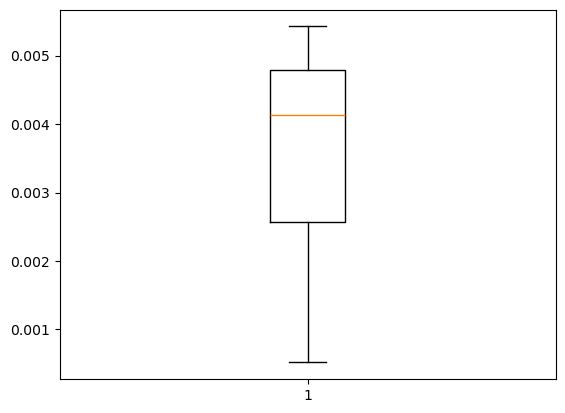

In [6]:
import matplotlib.pyplot as plt

plt.boxplot(data['local_max'])

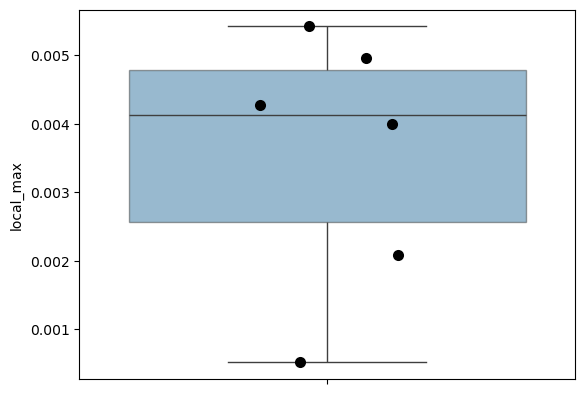

In [8]:
import seaborn as sns

# 1. Create the box plot (hide default outlier fliers)
sns.boxplot(data=data, y="local_max", boxprops=dict(alpha=0.5))

# 2. Overlay the individual data points
sns.stripplot(data=data, y="local_max", color="black", size=8, jitter=0.2)

# Show the visualization
plt.show()

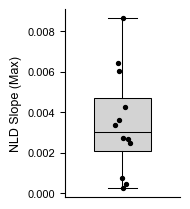

median max NLD slope: 0.00303
mean max NLD slope: 0.00347


In [8]:
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(2.0, 2.2))

values = data['local_max'].values

ax.boxplot(values,
           widths=0.5,
           patch_artist=True,
           showfliers=False,
           whis=[0, 100],
           boxprops=dict(facecolor='lightgrey', edgecolor='black', linewidth=0.75),
           medianprops=dict(color='black', linewidth=0.75),
           whiskerprops=dict(color='black', linewidth=0.75),
           capprops=dict(color='black', linewidth=0.75))

x_jit = 1 + rng.normal(0, 0.05, size=len(values))
ax.scatter(x_jit, values, s=8, edgecolor='black', facecolor='black', zorder=3)

ax.set_ylabel('NLD Slope (Max)', fontsize=9)
ax.set_xticks([])
ax.tick_params(labelsize=8, width=0.75)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig_out = './dataFolder/Figures/6c_NLDCurvature/selectedUnits/'
os.makedirs(fig_out, exist_ok=True)
plt.tight_layout()
fig.savefig(fig_out + 'nld_curvature_boxplot.pdf', bbox_inches='tight')
plt.show()

print(f'median max NLD slope: {data["local_max"].median():.5f}')
print(f'mean max NLD slope: {data["local_max"].mean():.5f}')

os.makedirs('./dataFolder/SummaryValuesFinal', exist_ok=True); pd.DataFrame({'metric': ['median_max_NLD_slope', 'mean_max_NLD_slope'], 'value': [data['local_max'].median(), data['local_max'].mean()]}).to_csv('./dataFolder/SummaryValuesFinal/nld_curvature_summary_stats.csv', index=False)

In [7]:
print(data[['mothID', 'local_max']]
      .sort_values('local_max', ascending=False)
      .to_string(index=False))

    mothID  local_max
m29_unit_3   0.008668
m23_unit_1   0.006430
m29_unit_1   0.006023
m31_unit_2   0.004258
m11_unit_1   0.003619
m30_unit_1   0.003342
m29_unit_2   0.002712
m11_unit_2   0.002670
m31_unit_1   0.002490
m30_unit_2   0.000751
m31_unit_3   0.000466
m11_unit_3   0.000243


In [8]:
moth_unit_id = 'm29_unit_3'

fp = [f for f in glob.glob('./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/*_EncodingModel.pickle')
      if moth_unit_id in f][0]

with open(fp, 'rb') as f:
    d = pickle.load(f)

n_ste_full   = np.asarray(d[9]).ravel()     # spike counts per bin, full/unclipped
bin_centers  = np.asarray(d[11]).ravel()    # full bin centers
p_spike      = np.asarray(d[13]).ravel()    # clipped nld_fwdModel
bins         = np.asarray(d[12]).ravel()    # clipped bin_fwdModel

# recompute max point-to-point slope, same as 6c cell 3
dx = np.diff(bins)
dp = np.diff(p_spike)
slopes = dp / dx
max_slope_idx = np.argmax(slopes)

bin_pre  = bins[max_slope_idx]
bin_post = bins[max_slope_idx + 1]
print(f'max slope: {slopes[max_slope_idx]:.5f} between bin {bin_pre:.3f} and {bin_post:.3f}')

# match these clipped bin values back to the full bin_centers to find their spike counts
idx_pre  = np.argmin(np.abs(bin_centers[:-1] - bin_pre))
idx_post = np.argmin(np.abs(bin_centers[:-1] - bin_post))

print(f'n_ste at bin {bin_pre:.3f}: {n_ste_full[idx_pre]}')
print(f'n_ste at bin {bin_post:.3f}: {n_ste_full[idx_post]}')

max slope: 0.00867 between bin 1.815 and 2.294
n_ste at bin 1.815: 742.0
n_ste at bin 2.294: 618.0
